# Cybersecurity Risk - CISA Known Exploited Vulnerabilities (KEV) 2021-2022
## Data Understanding · Data Cleaning · Visualisations exploratoires
**Source** : catalogue CISA des vulnérabilités activement exploitées (KEV), enrichi avec des informations NVD (CVSS, CWE, vecteur d'attaque).

In [35]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt,seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep'); plt.rcParams['figure.dpi']=100

raw= pd.read_csv("2022-06-08-enriched.csv")
df = raw.copy()

# 1. Data Understanding

## 1.1 Premier aperçu

In [36]:
print(f"Lignes : {df.shape[0]:,} | Colonnes : {df.shape[1]}")
df.head(5)

Lignes : 774 | Colonnes : 16


,cve_id,vendor_project,product,vulnerability_name,date_added,short_description,required_action,due_date,notes,grp,pub_date,cvss,cwe,vector,complexity,severity
0,CVE-2021-27104,accellion,FTA,Accellion FTA OS Command Injection Vulnerability,2021-11-03,Accellion FTA 9_12_370 and earlier is affected...,Apply updates per vendor instructions.,2021-11-17,NaN,1,2021-02-16,9.8,CWE-78,NETWORK,LOW,CRITICAL
1,CVE-2021-27102,accellion,FTA,Accellion FTA OS Command Injection Vulnerability,2021-11-03,Accellion FTA 9_12_411 and earlier is affected...,Apply updates per vendor instructions.,2021-11-17,NaN,1,2021-02-16,7.8,CWE-78,LOCAL,LOW,HIGH
2,CVE-2021-27101,accellion,FTA,Accellion FTA SQL Injection Vulnerability,2021-11-03,Accellion FTA 9_12_370 and earlier is affected...,Apply updates per vendor instructions.,2021-11-17,NaN,1,2021-02-16,9.8,CWE-89,NETWORK,LOW,CRITICAL
3,CVE-2021-27103,accellion,FTA,Accellion FTA SSRF Vulnerability,2021-11-03,Accellion FTA 9_12_411 and earlier is affected...,Apply updates per vendor instructions.,2021-11-17,NaN,1,2021-02-16,9.8,CWE-918,NETWORK,LOW,CRITICAL
4,CVE-2021-21017,adobe,Acrobat and Reader,Adobe Acrobat and Reader Heap-based Buffer Ove...,2021-11-03,Acrobat Reader DC versions versions 2020.013.2...,Apply updates per vendor instructions.,2021-11-17,NaN,1,2021-02-11,8.8,CWE-787,NETWORK,LOW,HIGH


In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 774 entries, 0 to 773
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cve_id              774 non-null    object 
 1   vendor_project      774 non-null    object 
 2   product             773 non-null    object 
 3   vulnerability_name  774 non-null    object 
 4   date_added          774 non-null    object 
 5   short_description   768 non-null    object 
 6   required_action     774 non-null    object 
 7   due_date            774 non-null    object 
 8   notes               0 non-null      float64
 9   grp                 774 non-null    int64  
 10  pub_date            765 non-null    object 
 11  cvss                609 non-null    float64
 12  cwe                 760 non-null    object 
 13  vector              609 non-null    object 
 14  complexity          609 non-null    object 
 15  severity            609 non-null    object 
dtypes: float

## 1.2 Dictionnaire des variables

| Variable | Type | Description |
|---|---|---|
| cve_id | Identifiant | Identifiant unique de la vulnérabilité (CVE) |
| vendor_project | Catégorielle | Éditeur / projet concerné |
| product | Catégorielle | Produit concerné |
| vulnerability_name | Texte | Nom de la vulnérabilité |
| date_added | Date | Date d'ajout au catalogue KEV de la CISA |
| short_description | Texte | Description courte |
| required_action | Texte | Action pour fixé |
| due_date | Date | Date limite pour fixé |
| notes | Texte | Liens / remarques (très souvent vide) |
| grp | Entier | Numéro du lot d'ajout au catalogue (une date d'ajout = un lot) |
| pub_date | Date | Date de publication de la CVE (NVD) |
| cvss | Numérique | Score CVSS (0 à 10) |
| cwe | Catégorielle | Type de faiblesse (CWE), parfois plusieurs |
| vector | Catégorielle | Vecteur d'attaque (NETWORK, LOCAL, ADJACENT_NETWORK) |
| complexity | Catégorielle | Complexité de l'attaque (LOW / HIGH) |
| severity | Catégorielle ordinale | Gravité (LOW, MEDIUM, HIGH, CRITICAL) |

## 1.3 Statistiques descriptives

In [38]:
df.describe(include='number').T

,count,mean,std,min,25%,50%,75%,max
notes,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
grp,774.0,13.434109,12.225148,1.0,1.0,16.0,20.0,37.0
cvss,609.0,8.422496,1.301657,3.1,7.8,8.8,9.8,10.0


In [39]:
txt = ['vendor_project','product','cwe','vector','complexity','severity','required_action']
df[txt].describe().T

,count,unique,top,freq
vendor_project,774,132,microsoft,231
product,773,346,Windows,78
cwe,760,80,NVD-CWE-noinfo,120
vector,609,3,NETWORK,450
complexity,609,2,LOW,553
severity,609,4,HIGH,338
required_action,774,7,Apply updates per vendor instructions.,722


In [40]:
# Conversion des colonnes en format datetime
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')
df['pub_date'] = pd.to_datetime(df['pub_date'], errors='coerce')

# Analyse des périodes
print("Période d'ajout au KEV :",df['date_added'].min().date(), '→',df['date_added'].max().date())

print("Période de publication des CVE :",df['pub_date'].min().date(), '→',df['pub_date'].max().date())

print("CVE distincts :", df['cve_id'].nunique(),"sur", len(df), "lignes")

Période d'ajout au KEV : 2021-11-03 → 2022-06-08
Période de publication des CVE : 2002-06-25 → 2022-06-03
CVE distincts : 774 sur 774 lignes


# 2. Diagnostic de qualité des données

## 2.1 Valeurs manquantes

In [41]:
miss = pd.DataFrame({'manquantes':df.isna().sum(), '%':(df.isna().mean()*100).round(1)})
miss[miss.manquantes>0].sort_values('%', ascending=False)

,manquantes,%
notes,774,100.0
cvss,165,21.3
vector,165,21.3
complexity,165,21.3
severity,165,21.3
cwe,14,1.8
pub_date,9,1.2
short_description,6,0.8
product,1,0.1


## 2.2 Doublons : le problème principal

In [42]:
print("Lignes totales          :", len(df))
print("CVE distincts           :", df['cve_id'].nunique())
print("Lignes strictement identiques :", df.duplicated().sum())
print("Lignes redondantes (même cve_id) :", df['cve_id'].duplicated().sum())
copies = df['cve_id'].value_counts().value_counts().sort_index()
copies

Lignes totales          : 774
CVE distincts           : 774
Lignes strictement identiques : 0
Lignes redondantes (même cve_id) : 0


count
1    774
Name: count, dtype: int64

In [43]:
# Les copies sont-elles complémentaires ? (une copie a le CVSS, l'autre est vide)
g = df.groupby('cve_id')

tmp = g.agg(nb_lignes=('cvss','size'), cvss_renseigne=('cvss','count'))
print("CVE dont certaines copies ont le CVSS et d'autres non :", ((tmp.cvss_renseigne>0)&(tmp.cvss_renseigne<tmp.nb_lignes)).sum())
print("CVE sans aucun CVSS :", (tmp.cvss_renseigne==0).sum())

CVE dont certaines copies ont le CVSS et d'autres non : 0
CVE sans aucun CVSS : 165


## 2.3 Valeurs suspectes et cohérence

In [44]:
import pandas as pd

# 1. Conversion des colonnes de dates
date_cols = ['date_added', 'pub_date', 'due_date']

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# 2. Conversion de CVSS en numérique
df['cvss'] = pd.to_numeric(df['cvss'], errors='coerce')

# 3. Une seule ligne par CVE
c = df.groupby('cve_id').first().reset_index()

# 4. Calcul des délais
c['remediation_days'] = (c['due_date'] - c['date_added']).dt.days
c['kev_lag_days'] = (c['date_added'] - c['pub_date']).dt.days

# 5. Vérification des incohérences
print("Date limite AVANT la date d'ajout :", (c['remediation_days'] < 0).sum(), "CVE")

print("Ajout au KEV AVANT la publication :", (c['kev_lag_days'] < 0).sum(), "CVE")

print("CWE 'NVD-CWE-noinfo' / 'Other' :", c['cwe'].fillna('').str.contains('NVD-CWE').sum(), "CVE")

print("Casse / espaces incohérents (vendor) :",(df['vendor_project'] !=df['vendor_project'].str.strip().str.lower()).sum())

# 6. Cohérence entre CVSS et severity
bins = pd.cut(df['cvss'],[0, 3.95, 6.95, 8.95, 10],labels=['LOW', 'MEDIUM', 'HIGH', 'CRITICAL'])
print("Incohérences cvss/severity :",((bins.astype(str) != df['severity'].astype(str)) & df['cvss'].notna()).sum())

# 7. Afficher les 6 premières anomalies
print("\nExemples de dates limites antérieures à la date d'ajout :")

display(c[c['remediation_days'] < 0][['cve_id', 'vendor_project', 'date_added','due_date', 'remediation_days']].head(6))

Date limite AVANT la date d'ajout : 15 CVE
Ajout au KEV AVANT la publication : 10 CVE
CWE 'NVD-CWE-noinfo' / 'Other' : 132 CVE
Casse / espaces incohérents (vendor) : 0
Incohérences cvss/severity : 0

Exemples de dates limites antérieures à la date d'ajout :


,cve_id,vendor_project,date_added,due_date,remediation_days
378,CVE-2019-11510,pulse secure,2021-11-03,2021-04-23,-194
455,CVE-2020-0601,microsoft,2021-11-03,2020-01-29,-644
486,CVE-2020-1350,microsoft,2021-11-03,2020-07-24,-467
491,CVE-2020-1472,microsoft,2021-11-03,2020-09-21,-408
558,CVE-2020-8243,pulse secure,2021-11-03,2021-04-23,-194
559,CVE-2020-8260,pulse secure,2021-11-03,2021-04-23,-194


# 3. Data Cleaning

## 3.1 Nettoyage du texte et consolidation des doublons

In [45]:
df = raw.copy()
# a) Nettoyage texte
for col in ['vendor_project','product','vulnerability_name','short_description','required_action','cwe']:
    df[col] = df[col].astype('string').str.strip()  #(changer les type de données)
df['vendor_project'] = df['vendor_project'].str.lower()

# b) Suppression des doublons stricts
n0 = len(df); df = df.drop_duplicates(); print("Doublons stricts supprimés :", n0-len(df))

# c) Consolidation : 1 ligne par CVE (première valeur non nulle de chaque colonne)
def join_unique(s):
    vals = pd.unique(s.dropna())
    return ';'.join(vals) if len(vals) else np.nan
cwe_all = df.groupby('cve_id')['cwe'].agg(join_unique).rename('cwe_all')
clean = df.groupby('cve_id', as_index=False).first()
clean = clean.drop(columns='cwe').merge(cwe_all, on='cve_id', how='left')
print("Lignes après consolidation :", len(clean), "| CVE distincts :", clean['cve_id'].nunique())
print("*********************")
df.info()

Doublons stricts supprimés : 0
Lignes après consolidation : 774 | CVE distincts : 774
*********************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 774 entries, 0 to 773
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cve_id              774 non-null    object 
 1   vendor_project      774 non-null    string 
 2   product             773 non-null    string 
 3   vulnerability_name  774 non-null    string 
 4   date_added          774 non-null    object 
 5   short_description   768 non-null    string 
 6   required_action     774 non-null    string 
 7   due_date            774 non-null    object 
 8   notes               0 non-null      float64
 9   grp                 774 non-null    int64  
 10  pub_date            765 non-null    object 
 11  cvss                609 non-null    float64
 12  cwe                 760 non-null    string 
 13  vector              609 non-null    object 
 14

Lignes après consolidation : 860 | CVE distincts : 860


## 3.2 Traitement des valeurs manquantes

In [46]:
clean['product'] = clean['product'].fillna('Unknown')
clean['short_description'] = clean['short_description'].fillna(clean['vulnerability_name'])
clean['has_notes'] = clean['notes'].notna()
clean['has_cvss'] = clean['cvss'].notna()
clean['cwe_all'] = clean['cwe_all'].fillna('Unknown')
# cvss / severity / vector / complexity / pub_date : conservés à NaN (valeurs manquantes structurelles, pas d'imputation)
clean.isna().sum()[lambda s: s>0]

notes         774
pub_date        9
cvss          165
vector        165
complexity    165
severity      165
dtype: int64

## 3.3 Typage et variables dérivées

In [47]:

# 1. Conversion des colonnes de dates
date_cols = ['due_date', 'date_added', 'pub_date']

for col in date_cols:
    clean[col] = pd.to_datetime(clean[col], errors='coerce')

# 2. Conversion CVSS en numérique
clean['cvss'] = pd.to_numeric(clean['cvss'], errors='coerce')

# 3. Severity ordonnée
clean['severity'] = pd.Categorical( clean['severity'], categories=['LOW', 'MEDIUM', 'HIGH', 'CRITICAL'], ordered=True)
# 4. Variables catégorielles
for col in ['vendor_project', 'product', 'vector', 'complexity']:
    clean[col] = clean[col].astype('category')

# 5. Calcul des délais
clean['remediation_days'] = (clean['due_date'] - clean['date_added']).dt.days

clean['kev_lag_days'] = (clean['date_added'] - clean['pub_date']).dt.days

clean['past_due_at_add'] = clean['remediation_days'] < 0
clean['added_before_pub'] = clean['kev_lag_days'] < 0

# 6. Extraction des dates
clean['added_year'] = clean['date_added'].dt.year
clean['added_month'] = clean['date_added'].dt.to_period('M').astype(str)
clean['pub_year'] = clean['pub_date'].dt.year

# 7. CWE principal et nombre de CWE
clean['cwe_all'] = clean['cwe_all'].fillna('Unknown').astype(str)

clean['cwe_main'] = (clean['cwe_all'].str.split(';').str[0].str.split(',').str[0].str.strip())

clean['cwe_count'] = clean['cwe_all'].apply(lambda s: 0 if s.strip() in ['', 'Unknown']
    else len([x for x in s.replace(',', ';').split(';') if x.strip()]))

clean['cwe_informative'] = ~clean['cwe_main'].isin(
    ['Unknown', 'NVD-CWE-noinfo', 'NVD-CWE-Other'])

# 8. Type d'action requise
ra = clean['required_action'].fillna('').astype(str).str.lower()

clean['action_type'] = np.where(ra.str.contains('end-of-life|end of life', regex=True),'End-of-life',
    np.where(ra.str.startswith('apply updates per vendor'),'Patch','Autre'))

# 9. Bande CVSS
clean['cvss_band'] = pd.cut( clean['cvss'],bins=[0, 3.95, 6.95, 8.95, 10],labels=['Low', 'Medium', 'High', 'Critical'])

# 10. Vendors principaux
top10 = clean['vendor_project'].value_counts().head(10).index

clean['vendor_top'] = np.where(clean['vendor_project'].isin(top10),clean['vendor_project'].astype(str),'autres')

# 11. Suppression des colonnes inutiles si elles existent
clean = clean.drop( columns=['notes', 'grp'],errors='ignore')

# 12. Création de la variable batch
clean['batch'] = (clean['date_added'].rank(method='dense').astype('Int64')
)

# 13. Affichage du résultat
print("Transformation terminée avec succès !")
print("Dimensions du dataset :", clean.shape)
print("\nTypes des colonnes :")
print(clean.dtypes)



Transformation terminée avec succès !
Dimensions du dataset : (774, 30)

Types des colonnes :
cve_id                        object
vendor_project              category
product                     category
vulnerability_name    string[python]
date_added            datetime64[ns]
short_description     string[python]
required_action       string[python]
due_date              datetime64[ns]
pub_date              datetime64[ns]
cvss                         float64
vector                      category
complexity                  category
severity                    category
cwe_all                       object
has_notes                       bool
has_cvss                        bool
remediation_days               int64
kev_lag_days                 float64
past_due_at_add                 bool
added_before_pub                bool
added_year                     int32
added_month                   object
pub_year                     float64
cwe_main                      object
cwe_count         


## 1.2 Dictionnaire des variables

| Variable | Type | Description |
|---|---|---|
| cve_id | Identifiant | Identifiant unique de la vulnérabilité (CVE) |
| vendor_project | Catégorielle | Éditeur / projet concerné |
| product | Catégorielle | Produit concerné |
| vulnerability_name | Texte | Nom de la vulnérabilité |
| date_added | Date | Date d'ajout au catalogue KEV de la CISA |
| short_description | Texte | Description courte de la vulnérabilité |
| required_action | Texte | Action recommandée pour corriger la vulnérabilité |
| due_date | Date | Date limite pour appliquer les mesures de remédiation |
| pub_date | Date | Date de publication de la CVE (NVD) |
| cvss | Numérique | Score CVSS (0 à 10) |
| cwe_all | Texte | Ensemble des codes CWE associés à la vulnérabilité |
| vector | Catégorielle | Vecteur d'attaque (NETWORK, LOCAL, ADJACENT_NETWORK) |
| complexity | Catégorielle | Complexité de l'attaque (LOW / HIGH) |
| severity | Catégorielle ordinale | Gravité (LOW, MEDIUM, HIGH, CRITICAL) |
| has_notes | Booléen | Indique si des notes ou remarques complémentaires sont disponibles |
| has_cvss | Booléen | Indique si le score CVSS est disponible |
| remediation_days | Entier | Nombre de jours entre la date d'ajout au KEV et la date limite de remédiation |
| kev_lag_days | Numérique | Nombre de jours entre la publication de la CVE et son ajout au KEV |
| past_due_at_add | Booléen | Indique si la date limite de remédiation est dépassée au moment de l'ajout au KEV |
| added_before_pub | Booléen | Indique si la CVE a été ajoutée au KEV avant sa date de publication |
| added_year | Entier | Année d'ajout de la vulnérabilité au catalogue KEV |
| added_month | Texte | Mois d'ajout au KEV au format AAAA-MM |
| pub_year | Numérique | Année de publication de la CVE |
| cwe_main | Texte | Premier code CWE extrait de la liste des CWE associés à la vulnérabilité |
| cwe_count | Entier | Nombre de codes CWE associés à chaque vulnérabilité |
| cwe_informative | Booléen | Indique si la classification CWE est informative ou non |
| action_type | Catégorielle | Type d'action requis (End-of-life, Patch ou Autre) |
| vendor_top | Catégorielle | Identifie les 10 fournisseurs les plus fréquents ; les autres sont regroupés dans « autres » |
| batch | Entier nullable | Rang chronologique dense de la date d'ajout au KEV ; les CVE ayant la même date reçoivent le même numéro |

## 3.4 Contrôles finaux et export

In [48]:
assert clean['cve_id'].is_unique
print("Shape finale :", clean.shape)

clean.to_csv('cisa_kev_clean.csv', index=False)
print("→ fichier cisa_kev_clean.csv exporté")

Shape finale : (774, 30)
→ fichier cisa_kev_clean.csv exporté


→ fichier cisa_kev_clean.csv exporté


# 4. Visualisations exploratoires

Les analyses se font sur les **774 CVE uniques** (données consolidées).

## 4.1 Évolution des ajouts au catalogue KEV

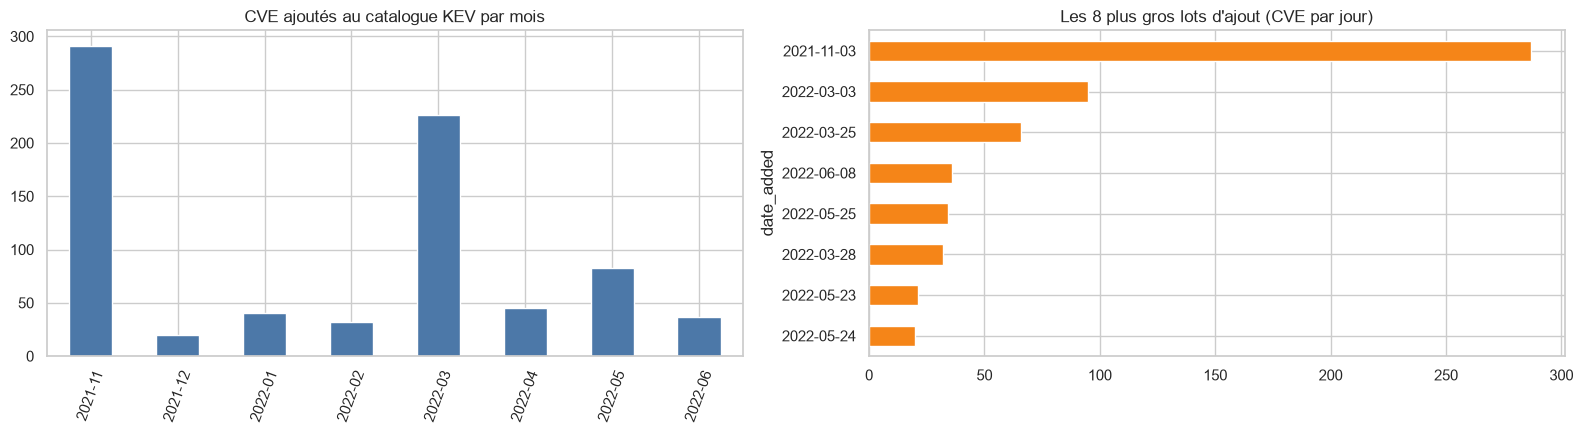

In [49]:
m = clean.groupby('added_month').size()
fig, ax = plt.subplots(1,2, figsize=(16,4.5))
m.plot.bar(ax=ax[0], color='#4C78A8'); ax[0].set_title('CVE ajoutés au catalogue KEV par mois'); ax[0].set_xlabel('')
ax[0].tick_params(axis='x', rotation=70)
b = clean.groupby('date_added').size().sort_values(ascending=False).head(8)
b.index = b.index.strftime('%Y-%m-%d'); b.plot.barh(ax=ax[1], color='#F58518'); ax[1].invert_yaxis()
ax[1].set_title("Les 8 plus gros lots d'ajout (CVE par jour)")
plt.tight_layout(); plt.show()

Le premier lot du **3 novembre 2021** (lancement du catalogue) contient à lui seul une grande part des CVE, avec un gros rattrapage de vulnérabilités historiques.

## 4.2 Éditeurs et produits les plus touchés

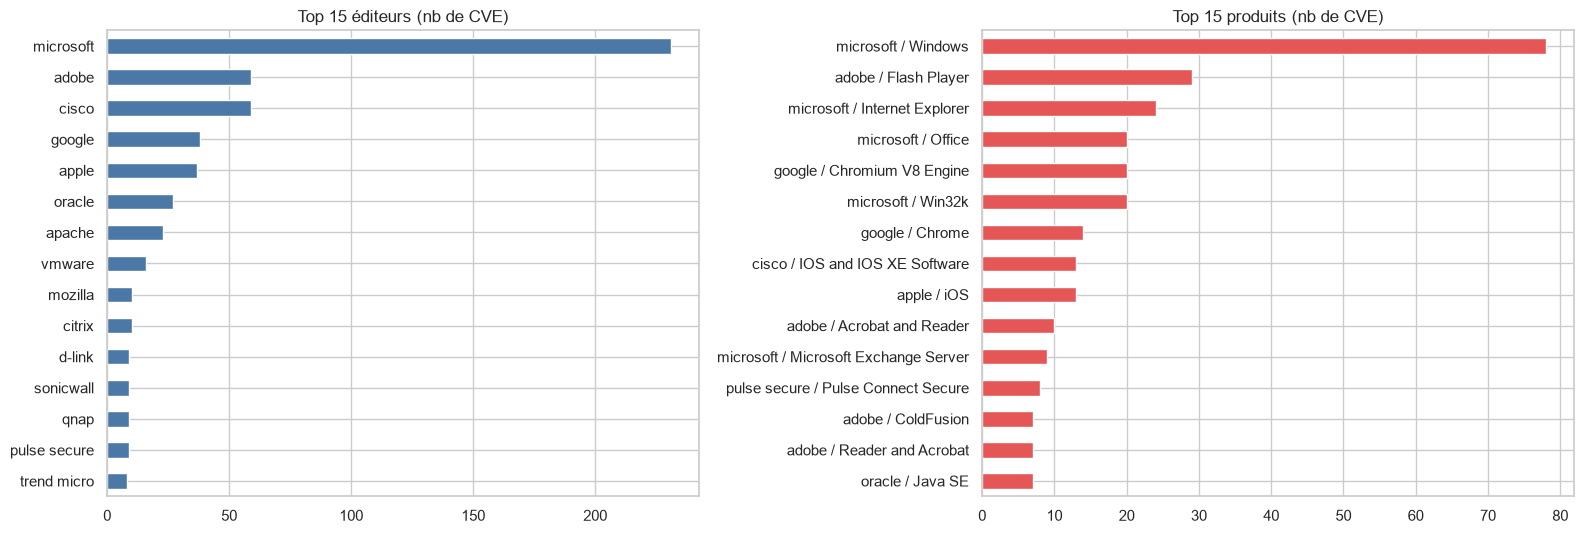

Microsoft représente 29.8% des CVE ; les 5 premiers éditeurs : 54.8%


In [50]:
fig, ax = plt.subplots(1,2, figsize=(16,5.5))
clean['vendor_project'].value_counts().head(15).sort_values().plot.barh(ax=ax[0], color='#4C78A8'); ax[0].set_title('Top 15 éditeurs (nb de CVE)')
p = clean.groupby(['vendor_project','product'], observed=True).size().sort_values(ascending=False).head(15).sort_values()
p.index = [f"{a} / {b}" for a,b in p.index]; p.plot.barh(ax=ax[1], color='#E45756'); ax[1].set_title('Top 15 produits (nb de CVE)')
for a in ax: a.set_ylabel('')
plt.tight_layout(); plt.show()
print(f"Microsoft représente {(clean['vendor_project']=='microsoft').mean()*100:.1f}% des CVE ; les 5 premiers éditeurs : {clean['vendor_project'].value_counts(normalize=True).head(5).sum()*100:.1f}%")

## 4.3 Gravité : CVSS, severity, vecteur et complexité

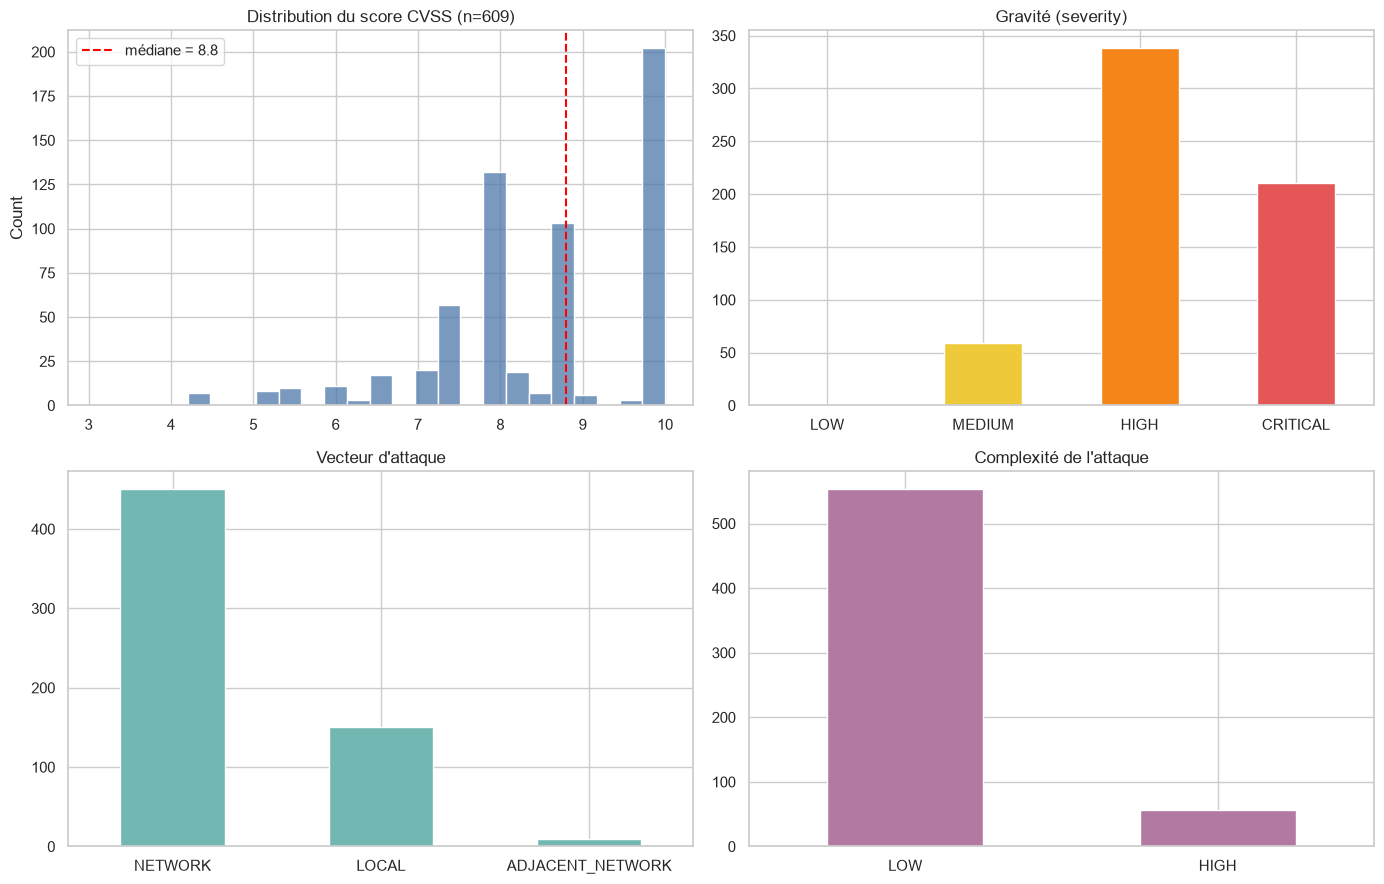

In [51]:
cv = clean[clean.has_cvss]
fig, ax = plt.subplots(2,2, figsize=(14,9))
sns.histplot(cv['cvss'], bins=25, ax=ax[0,0], color='#4C78A8'); ax[0,0].set_title(f'Distribution du score CVSS (n={len(cv)})')
ax[0,0].axvline(cv['cvss'].median(), color='red', ls='--', label=f"médiane = {cv['cvss'].median()}"); ax[0,0].legend()
cv['severity'].value_counts().reindex(['LOW','MEDIUM','HIGH','CRITICAL']).plot.bar(ax=ax[0,1], color=['#54A24B','#EECA3B','#F58518','#E45756'], rot=0); ax[0,1].set_title('Gravité (severity)')
cv['vector'].value_counts().plot.bar(ax=ax[1,0], rot=0, color='#72B7B2'); ax[1,0].set_title("Vecteur d'attaque")
cv['complexity'].value_counts().plot.bar(ax=ax[1,1], rot=0, color='#B279A2'); ax[1,1].set_title("Complexité de l'attaque")
for a in ax.ravel(): a.set_xlabel('')
plt.tight_layout(); plt.show()

La très grande majorité des vulnérabilités exploitées sont **HIGH ou CRITICAL**, attaquables **par le réseau** et de **faible complexité** : ce sont les plus faciles à exploiter.

## 4.4 Types de faiblesses (CWE)

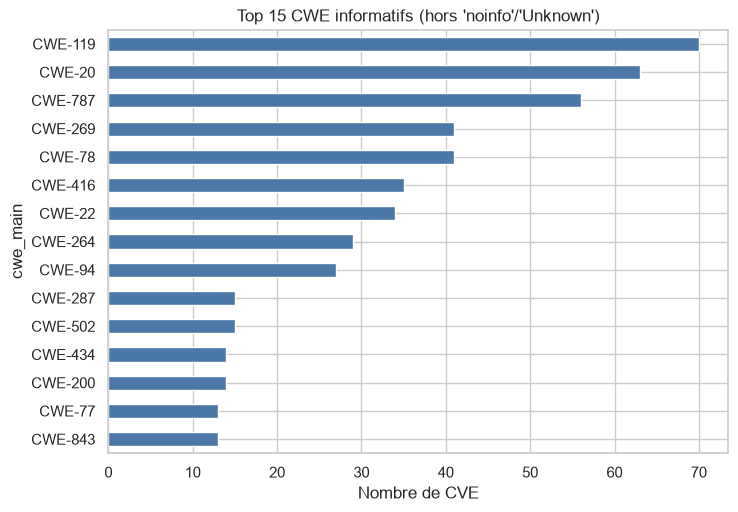

CWE non informatif (noinfo/other/inconnu) : 19% des CVE


In [52]:
cw = clean[clean.cwe_informative]['cwe_main'].value_counts().head(15).sort_values()
plt.figure(figsize=(8,5.5)); cw.plot.barh(color='#4C78A8')
plt.title(f"Top 15 CWE informatifs (hors 'noinfo'/'Unknown')"); plt.xlabel('Nombre de CVE'); plt.show()
print(f"CWE non informatif (noinfo/other/inconnu) : {(~clean.cwe_informative).mean()*100:.0f}% des CVE")

Principaux CWE : CWE-119 / CWE-787 / CWE-416 (corruption mémoire), CWE-20 (validation d'entrée), CWE-78 (injection de commande), CWE-269 (privilèges), CWE-22 (path traversal).

## 4.5 Délai entre publication de la CVE et ajout au KEV

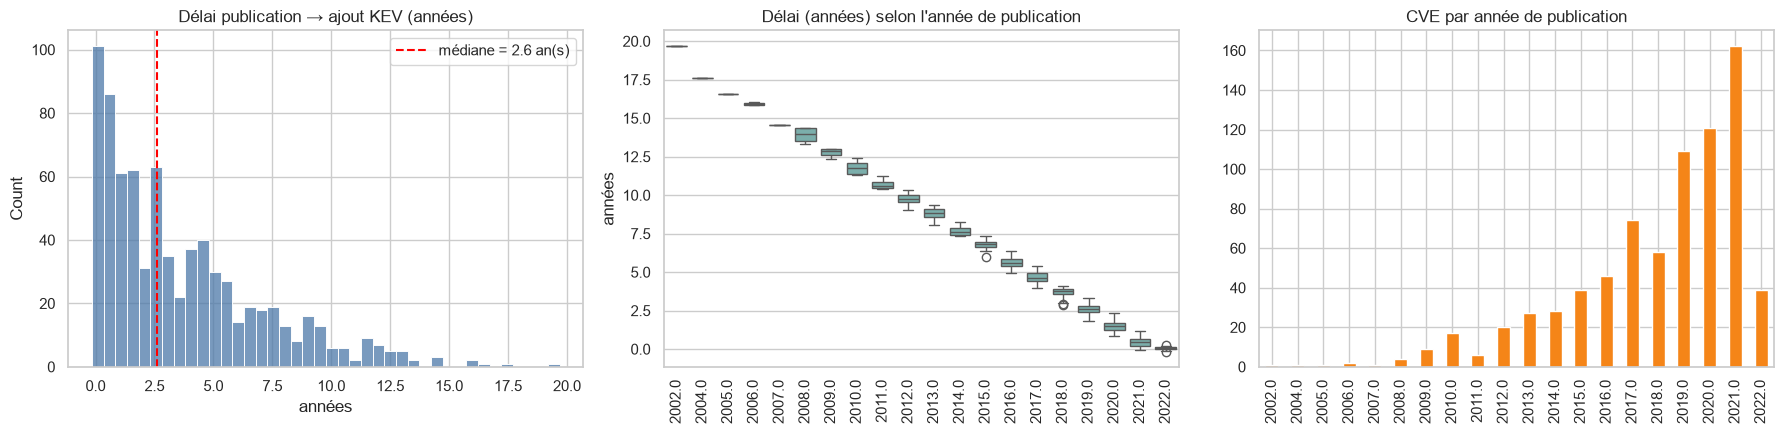

Médiane : 950 jours (2.6 ans) | 73% des CVE ont été ajoutés plus d'un an après leur publication


In [53]:
lag = clean['kev_lag_days'].dropna()
fig, ax = plt.subplots(1,3, figsize=(18,4.5))
sns.histplot(lag/365, bins=40, ax=ax[0], color='#4C78A8'); ax[0].set_title('Délai publication → ajout KEV (années)'); ax[0].set_xlabel('années')
ax[0].axvline(lag.median()/365, color='red', ls='--', label=f'médiane = {lag.median()/365:.1f} an(s)'); ax[0].legend()
sns.boxplot(data=clean.dropna(subset=['pub_year']), x='pub_year', y=clean['kev_lag_days']/365, ax=ax[1], color='#72B7B2')
ax[1].set_title('Délai (années) selon l\'année de publication'); ax[1].tick_params(axis='x', rotation=90); ax[1].set_xlabel(''); ax[1].set_ylabel('années')
clean['pub_year'].value_counts().sort_index().plot.bar(ax=ax[2], color='#F58518'); ax[2].set_title("CVE par année de publication"); ax[2].set_xlabel('')
plt.tight_layout(); plt.show()
print(f"Médiane : {lag.median():.0f} jours ({lag.median()/365:.1f} ans) | {(lag>365).mean()*100:.0f}% des CVE ont été ajoutés plus d'un an après leur publication")

Beaucoup de CVE **anciennes** restent exploitées plusieurs années après leur publication : un patch non appliqué reste une cible durable.

## 4.6 Délais de remédiation exigés

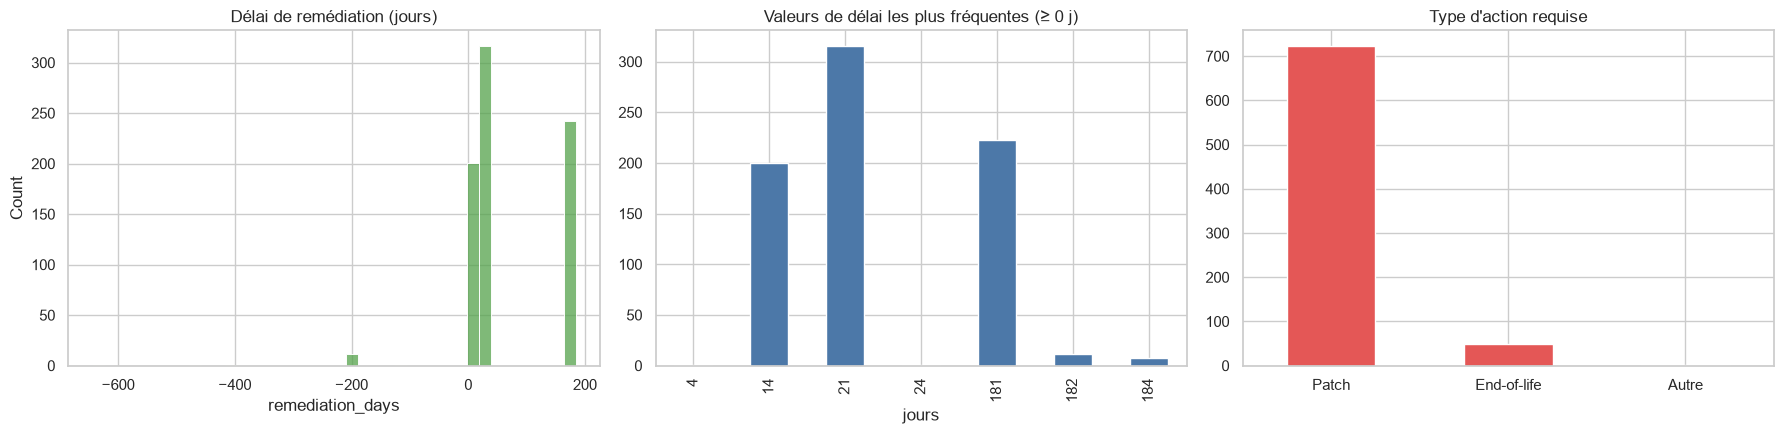

In [54]:
fig, ax = plt.subplots(1,3, figsize=(18,4.5))
sns.histplot(clean['remediation_days'], bins=40, ax=ax[0], color='#54A24B'); ax[0].set_title('Délai de remédiation (jours)')
rem = clean[clean.remediation_days>=0]['remediation_days'].value_counts().head(8)
rem.sort_index().plot.bar(ax=ax[1], color='#4C78A8'); ax[1].set_title('Valeurs de délai les plus fréquentes (≥ 0 j)'); ax[1].set_xlabel('jours')
clean['action_type'].value_counts().plot.bar(ax=ax[2], rot=0, color='#E45756'); ax[2].set_title('Type d\'action requise'); ax[2].set_xlabel('')
plt.tight_layout(); plt.show()

Les délais les plus fréquents sont **21 jours** (396 CVE), **14 jours** (200 CVE) et **181 jours** (223 CVE, essentiellement le lot de novembre 2021). Les délais négatifs correspondent aux échéances déjà dépassées à l'ajout.

## 4.7 Croisements

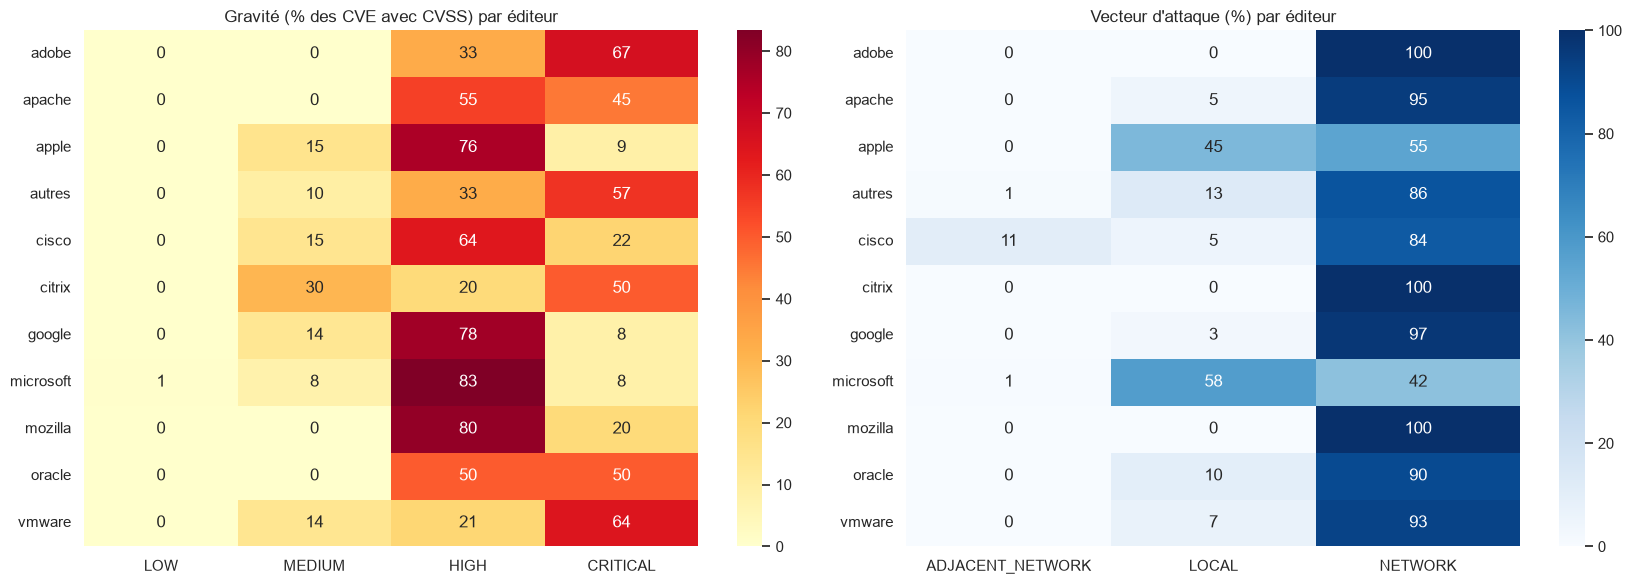

In [55]:
fig, ax = plt.subplots(1,2, figsize=(17,6))
t = pd.crosstab(clean['vendor_top'], clean['severity'], normalize='index').reindex(columns=['LOW','MEDIUM','HIGH','CRITICAL']).fillna(0)*100
sns.heatmap(t, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax[0]); ax[0].set_title('Gravité (% des CVE avec CVSS) par éditeur')
t2 = pd.crosstab(clean['vendor_top'], clean['vector'], normalize='index')*100
sns.heatmap(t2, annot=True, fmt='.0f', cmap='Blues', ax=ax[1]); ax[1].set_title("Vecteur d'attaque (%) par éditeur")
for a in ax: a.set_ylabel(''); a.set_xlabel('')
plt.tight_layout(); plt.show()

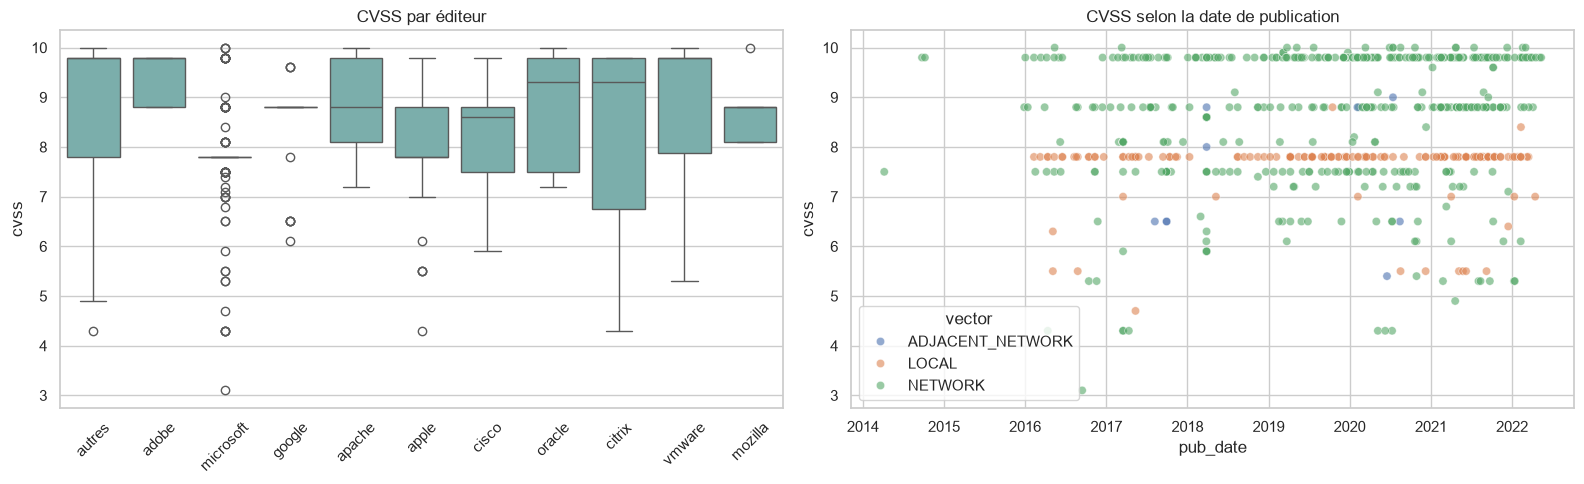

In [56]:
fig, ax = plt.subplots(1,2, figsize=(16,5))
sns.boxplot(data=cv, x='vendor_top', y='cvss', ax=ax[0], color='#72B7B2'); ax[0].tick_params(axis='x', rotation=45); ax[0].set_title('CVSS par éditeur'); ax[0].set_xlabel('')
sns.scatterplot(data=cv, x='pub_date', y='cvss', hue='vector', alpha=.6, ax=ax[1]); ax[1].set_title('CVSS selon la date de publication')
plt.tight_layout(); plt.show()

## 4.8 Corrélations et cartographie des valeurs manquantes

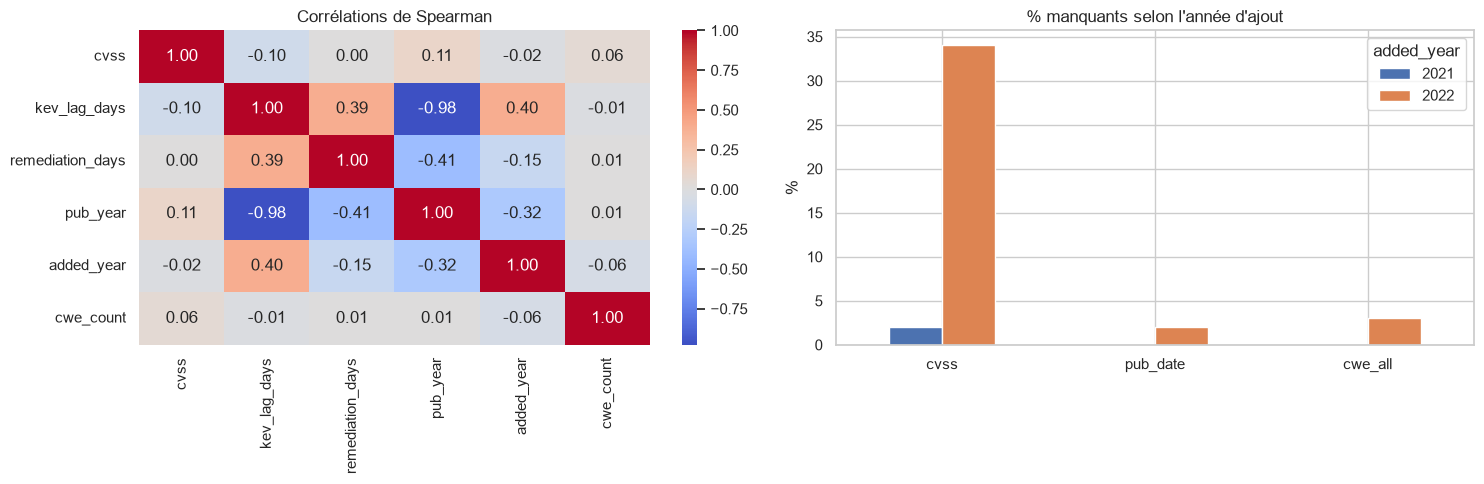

In [57]:
num = clean[['cvss','kev_lag_days','remediation_days','pub_year','added_year','cwe_count']].dropna()
fig, ax = plt.subplots(1,2, figsize=(15,5))
sns.heatmap(num.corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[0]); ax[0].set_title('Corrélations de Spearman')
mm = clean.groupby('added_year')[['cvss','pub_date','cwe_all']].agg(lambda s: s.isna().mean()*100)
mm['cwe_all'] = clean.groupby('added_year')['cwe_all'].apply(lambda s: (s=='Unknown').mean()*100)
mm.round(0).T.plot.bar(ax=ax[1], rot=0); ax[1].set_title("% manquants selon l'année d'ajout"); ax[1].set_ylabel('%')
plt.tight_layout(); plt.show()

Les données manquantes (CVSS, date de publication) se concentrent sur les CVE **ajoutées en 2022** : elles ne sont pas encore enrichies dans la source NVD utilisée. C'est un manque **systématique**, pas aléatoire.

# 5. Conclusions

In [58]:
print(f"• {len(raw):,} lignes brutes → {len(clean)} CVE uniques ({len(raw)/len(clean):.1f} lignes par CVE en moyenne)")
print(f"• {clean['vendor_project'].nunique()} éditeurs, {clean['product'].nunique()} produits | Microsoft : {(clean['vendor_project']=='microsoft').mean()*100:.0f}% des CVE")
print(f"• CVSS médian : {cv['cvss'].median()} | {(cv['severity'].isin(['HIGH','CRITICAL'])).mean()*100:.0f}% HIGH/CRITICAL | {(cv['vector']=='NETWORK').mean()*100:.0f}% par le réseau | {(cv['complexity']=='LOW').mean()*100:.0f}% de faible complexité")
!git remote add origin https://github.com/USERNAME/NOM-DU-REPO.git
!git branch -M main
!git push -u origin mainprint(f"• Délai médian publication → KEV : {lag.median():.0f} jours")

• 774 lignes brutes → 774 CVE uniques (1.0 lignes par CVE en moyenne)
• 132 éditeurs, 347 produits | Microsoft : 30% des CVE
• CVSS médian : 8.8 | 90% HIGH/CRITICAL | 74% par le réseau | 91% de faible complexité
• Délai médian publication → KEV : 950 jours


In [3]:
import os

git_path = r"C:\Program Files\Git\cmd"

os.environ["PATH"] = git_path + os.pathsep + os.environ["PATH"]

print("Git ajouté au PATH !")

Git ajouté au PATH !


In [4]:
!git --version

git version 2.56.1.windows.1


In [6]:
import os
print(os.getcwd())

C:\Users\Wiem\ProjectTutoré


In [5]:


!git remote add origin https://github.com/wiemab11/ProjetTuto.git
!git branch -M main
!git push -u origin main


fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
